# Mini Project: Image Classification with Data Augmentation (Cats vs Dogs)

In this project, I build an end-to-end convolutional neural network (CNN) pipeline to classify images of cats and dogs using data augmentation and regularization.

## Objectives
**What I learn**
- How to structure an image classification pipeline with Keras and TensorFlow
- How to subsample and stratify large image datasets for efficient CPU training
- How to apply real-time data augmentation with `ImageDataGenerator` to combat overfitting
- How to implement regularization: Dropout, EarlyStopping, and ReduceLROnPlateau
- How to evaluate binary classifiers with confusion matrices, precision, recall, and threshold analysis
- How to systematically quantify the generalization gap between baseline and augmented models
- How to export reproducible artifacts including model weights, configs, and prediction tables

## How I run this notebook
I open it in [Google Colab](https://colab.research.google.com) (**File → Upload notebook**) and run all cells from top to bottom (**Runtime → Run all**).
No DigitalOcean VM is required; the instructor noted that a remote VM is optional. I can run the whole notebook on CPU.
To keep CPU training times reasonable, I use 48×48 images (the assignment brief allows lowering the official 180×180 resolution) and a stratified subsample of 5,000 labeled training images.
The 80/20 train/val split is taken from that subsample and reused across every experiment for fair comparison.
Seeds are fixed in the setup cell at the top: 42 for Python, NumPy and TensorFlow, and 1337 for the stratified split and the shuffled training generators. Every model is re-seeded right before it is built. The numbers below come from the run whose outputs are saved in this notebook; a different machine or library version can give slightly different results.


**What this cell does:** fixes every random seed before any data or model is created, so that a re-run uses the same split and starting weights. `PYTHONHASHSEED` is not set here because Python only reads it when it starts, and nothing in this notebook depends on string hash order.

In [1]:
# Fix the random seeds first, before any data or model is created
import random
import numpy as np
import tensorflow as tf

SEED = 42            # Python, NumPy and TensorFlow
LOADER_SEED = 1337   # stratified train/val split and the Keras generators

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)               # sets the Python, NumPy and TensorFlow seeds together
tf.config.experimental.enable_op_determinism()     # ask TensorFlow for repeatable CPU operations

print(f"Seeds fixed: SEED={SEED}, LOADER_SEED={LOADER_SEED}")

I0000 00:00:1795355022.788795  196267 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795355022.853365  196267 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1795355023.927652  196267 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Seeds fixed: SEED=42, LOADER_SEED=1337


## 1. Download and prepare the dataset

First, I define `ensure_dataset()` to guarantee that the Dogs vs Cats dataset is present locally in `data/cats_dogs`.
If the dataset already exists locally, the function skips downloading. Otherwise, it downloads the zip archive from GitHub, extracts it to a temporary folder, locates the folder containing `train/` and `test/`, and moves it to `data/cats_dogs`.

**What this cell does:** defines and calls `ensure_dataset()` to prepare the Dogs vs Cats dataset in `data/cats_dogs`.

In [2]:
import os
import shutil
import zipfile
import urllib.request
from pathlib import Path

def ensure_dataset():
    target_dir = Path("data/cats_dogs")
    
    # 1. Check if dataset already exists with images
    if target_dir.exists():
        train_exists = (target_dir / "train").exists()
        test_exists = (target_dir / "test").exists()
        if train_exists and test_exists:
            train_imgs = list((target_dir / "train").glob("**/*.jpg"))
            test_imgs = list((target_dir / "test").glob("**/*.jpg"))
            if len(train_imgs) > 0 and len(test_imgs) > 0:
                print(f"Dataset already exists at {target_dir.resolve()} with {len(train_imgs)} train and {len(test_imgs)} test images. Skipping download.")
                return target_dir
    
    # 2. Setup download location
    data_dir = Path("data")
    data_dir.mkdir(parents=True, exist_ok=True)
    zip_path = data_dir / "Dogs_vs_Cats.zip"
    
    # Check if cached locally in environment first
    cached_zip = Path("/workspace/datasets/Dogs_vs_Cats.zip")
    if not zip_path.exists():
        if cached_zip.exists():
            print(f"Found local cached dataset archive at {cached_zip}. Copying to {zip_path}...")
            shutil.copy(cached_zip, zip_path)
        else:
            url = "https://github.com/devtlv/Datasets-GEN-AI-Bootcamp/raw/refs/heads/main/Week%206/W6D5/Dogs%20vs%20Cats.zip"
            print(f"Downloading Dogs vs Cats dataset from {url}...")
            urllib.request.urlretrieve(url, zip_path)
            print("Download complete.")
            
    # 3. Extract to a temporary folder
    temp_extract = data_dir / "_temp_extract"
    if temp_extract.exists():
        shutil.rmtree(temp_extract)
    temp_extract.mkdir(parents=True, exist_ok=True)
    
    print("Extracting zip archive...")
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(temp_extract)
        
    # 4. Robustly locate folder containing both train/ and test/
    # The zip root contains train/ and test/ (each with nested train/ or test/ subfolders)
    candidate_root = None
    for root, dirs, _ in os.walk(temp_extract):
        if "train" in dirs and "test" in dirs:
            candidate_root = Path(root)
            break
            
    if candidate_root is None:
        # Fallback search for directory containing train
        for root, dirs, _ in os.walk(temp_extract):
            if "train" in dirs:
                candidate_root = Path(root)
                break
                
    if candidate_root is not None:
        if target_dir.exists():
            shutil.rmtree(target_dir)
        shutil.move(str(candidate_root), str(target_dir))
    else:
        if target_dir.exists():
            shutil.rmtree(target_dir)
        temp_extract.rename(target_dir)
        
    # Clean up temp folder if it still exists
    if temp_extract.exists():
        shutil.rmtree(temp_extract)
        
    print(f"Dataset ready at {target_dir.resolve()}.")
    return target_dir

dataset_path = ensure_dataset()

Dataset already exists at /workspace/DI_push/Week5/Day5/MiniProject/data/cats_dogs with 25000 train and 12500 test images. Skipping download.


## 2. Prefilled data loader with stratified subsampling

Now I set up the data pipeline following the prefilled loader template.
The file list is sorted first, so the split does not depend on the order in which the filesystem lists files.
Per project requirements:
- Image dimensions are set to `IMG_HEIGHT, IMG_WIDTH = 48, 48` for fast, reliable CPU execution.
- After constructing `df_train_full` and importing `train_test_split`, I perform a stratified subsample down to 5,000 images (`train_test_split(..., train_size=5000, stratify=df_train_full['label'], random_state=seed)`).
- The subsampled dataset is split 80/20 into `df_tr` and `df_val`, stratified by label.
- Three `ImageDataGenerator` flows are created:
  - `train_flow`: augmented with random rotations, translations, zooms, and horizontal flips.
  - `val_flow`: rescaled by `1./255` without augmentation. It is not shuffled, so the seed does not change its order.
  - `test_flow`: rescaled by `1./255`, unlabeled (`class_mode=None`, `shuffle=False`).

**What this cell does:** builds image DataFrames, subsamples 5,000 training images with stratification, splits into train and validation sets, and initializes the data generators.

In [3]:
# Extra imports used later in this notebook
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

# Prefilled. Just copy and execute.
# Allowed changes only: image size 48x48, and a stratified 5,000-image subsample for CPU training.
import os, math, re, random
from glob import glob
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# (random seeds were already fixed in the setup cell at the top)

# Paths - change if needed
DATA_ROOT = Path("data/cats_dogs")
train_dir = (DATA_ROOT / "train" / "train") if (DATA_ROOT / "train" / "train").exists() else (DATA_ROOT / "train")
test_dir  = (DATA_ROOT / "test"  / "test")  if (DATA_ROOT / "test"  / "test").exists()  else (DATA_ROOT / "test")

IMG_HEIGHT, IMG_WIDTH = 48, 48
batch_size = 32
seed = LOADER_SEED

# Build DataFrames from folders
def build_df_from_folder(folder: Path, labeled: bool=True):
    exts = ('*.jpg','*.jpeg','*.png','*.bmp')
    files = []
    for ex in exts:
        files.extend(glob(str(folder / '**' / ex), recursive=True))
    # Sort so the row order (and therefore the seeded split) does not depend on the filesystem
    files = sorted(files)
    if not files:
        raise FileNotFoundError(f"No images found under {folder}")
    rows = []
    for f in files:
        if labeled:
            name = Path(f).name.lower()
            parent = Path(f).parent.name.lower()
            if parent in {"cat","cats"}:
                label = "cat"
            elif parent in {"dog","dogs"}:
                label = "dog"
            else:
                if re.search(r'(^|[^a-z])cat([^a-z]|$)', name): label = "cat"
                elif re.search(r'(^|[^a-z])dog([^a-z]|$)', name): label = "dog"
                else:
                    continue
            rows.append({"filepath": f, "label": label})
        else:
            rows.append({"filepath": f})
    return pd.DataFrame(rows)

df_train_full = build_df_from_folder(train_dir, labeled=True)
full_labeled_pool_size = len(df_train_full)
df_test_full  = build_df_from_folder(test_dir,  labeled=False)

# Train validation split
from sklearn.model_selection import train_test_split

# CPU-friendly stratified subsample of the labeled training pool
N_SUBSAMPLE = 5000
if len(df_train_full) > N_SUBSAMPLE:
    df_train_full, _ = train_test_split(
        df_train_full, train_size=N_SUBSAMPLE,
        stratify=df_train_full["label"], random_state=seed
    )
    df_train_full = df_train_full.reset_index(drop=True)

print("Full labeled pool after subsample:", len(df_train_full))
print(df_train_full["label"].value_counts())

df_tr, df_val = train_test_split(
    df_train_full, test_size=0.2, stratify=df_train_full["label"], random_state=seed
)

# Generators
train_gen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=45,
    width_shift_range=0.15,
    height_shift_range=0.15,
    zoom_range=0.5,
    horizontal_flip=True,
)
val_gen = ImageDataGenerator(rescale=1./255)
test_gen = ImageDataGenerator(rescale=1./255)

train_flow = train_gen.flow_from_dataframe(
    df_tr, x_col="filepath", y_col="label",
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    class_mode="binary", batch_size=batch_size,
    shuffle=True, seed=seed, validate_filenames=False
)
val_flow = val_gen.flow_from_dataframe(
    df_val, x_col="filepath", y_col="label",
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    class_mode="binary", batch_size=batch_size,
    shuffle=False, validate_filenames=False
)
# Unlabeled test for inference only
test_flow = test_gen.flow_from_dataframe(
    df_test_full, x_col="filepath", y_col=None,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    class_mode=None, batch_size=batch_size,
    shuffle=False, validate_filenames=False
)

print({"train": train_flow.samples, "val": val_flow.samples, "test": test_flow.samples,
       "class_indices": train_flow.class_indices})

# Aliases so later cells can use either the official names or the shorter ones
BATCH_SIZE = batch_size
seed_val = seed
df_test = df_test_full.copy()
df_tr = df_tr.copy()
df_val = df_val.copy()
df_test["filename"] = df_test["filepath"].map(lambda p: Path(p).name)
df_tr["filename"] = df_tr["filepath"].map(lambda p: Path(p).name)
df_val["filename"] = df_val["filepath"].map(lambda p: Path(p).name)
print("Train/val/test sizes:", len(df_tr), len(df_val), len(df_test))


Full labeled pool after subsample: 5000
label
dog    2500
cat    2500
Name: count, dtype: int64
Found 4000 non-validated image filenames belonging to 2 classes.


Found 1000 non-validated image filenames belonging to 2 classes.


Found 12500 non-validated image filenames.


{'train': 4000, 'val': 1000, 'test': 12500, 'class_indices': {'cat': 0, 'dog': 1}}
Train/val/test sizes: 4000 1000 12500


## 3. Inspect the data

The full dataset contains 25,000 labeled training images and 12,500 unlabeled test images.
In the saved run, my stratified 5,000-image subsample contains exactly 2,500 cats and 2,500 dogs, preserving a balanced class ratio.
Following the 80/20 split in that run, the training split contains 4,000 images (2,000 cats, 2,000 dogs) and the validation split contains 1,000 images (500 cats, 500 dogs).

In the examples below, I see both close-ups and full-body views, with different poses, lighting and backgrounds. Pointed ears and whiskers can help me spot a cat, while muzzle shape and floppy ears can help me spot a dog. Some dogs also have pointed ears, so I look at several cues together.

**What this cell does:** visualizes a 3x4 grid of sample training images along with their ground-truth labels.

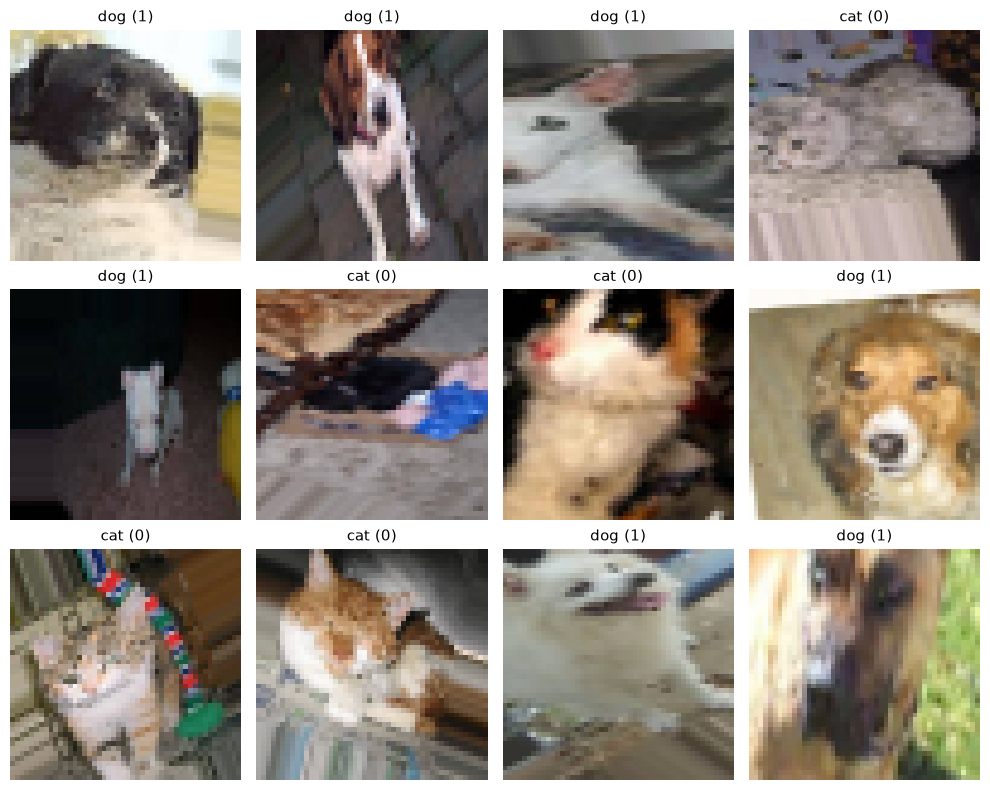

In [4]:
# Inspect a batch of training images
sample_batch_images, sample_batch_labels = next(iter(train_flow))
label_map_inv = {v: k for k, v in train_flow.class_indices.items()}

plt.figure(figsize=(10, 8))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(sample_batch_images[i])
    label_str = label_map_inv[int(sample_batch_labels[i])]
    plt.title(f"{label_str} ({int(sample_batch_labels[i])})", fontsize=11)
    plt.axis("off")
plt.tight_layout()
plt.show()

## 4. CNN Architecture

I build a convolutional neural network structured with two convolutional feature extraction blocks followed by a fully connected classification head.

The first convolutional block consists of a `Conv2D` layer with 32 filters of size 3×3 and ReLU activation, which can learn low-level spatial features such as directional edges, hair texture gradients, and color transitions. This is followed by a `MaxPool2D` layer with a 2×2 pool size that downsamples the spatial resolution from 48×48 to 24×24 and makes the features less sensitive to small shifts. A `Dropout(0.25)` layer immediately follows to discourage co-adaptation among activations during training.

The second convolutional block applies a `Conv2D` layer with 64 filters of size 3×3 and ReLU activation which can combine simpler features into patterns such as ear contours, nose contours, and eye patterns. This is followed by a second `MaxPool2D(2, 2)` layer downsampling the representations from 24×24 to 12×12, followed by another `Dropout(0.25)` layer.

The classification head begins with a `Flatten` layer that unrolls the 12×12×64 feature tensor into a 1D vector of 9,216 values. A `Dense` layer with 128 units and ReLU activation processes these spatial representations, followed by a substantial `Dropout(0.50)` layer to regularize the dense layer during training. Finally, an output `Dense` layer with 1 unit and a `sigmoid` activation produces a scalar probability between 0 and 1, representing the predicted probability that the input image is a dog (label 1).

When I train the network, I compile it with binary cross-entropy loss, which is the standard objective for a single sigmoid output that predicts a probability.
I wrap this construction inside `build_cnn()` so that the exact same architecture can be cleanly instantiated across all experiments.

**What this cell does:** defines `build_cnn()` and displays the model summary.

In [5]:
def build_cnn(input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)):
    """Constructs the standard Cats vs Dogs CNN architecture."""
    model = keras.Sequential([
        # Block 1
        layers.Input(shape=input_shape),
        layers.Conv2D(32, (3, 3), activation="relu", padding="same", name="conv1"),
        layers.MaxPool2D(pool_size=(2, 2), name="pool1"),
        layers.Dropout(0.25, name="dropout1"),
        
        # Block 2
        layers.Conv2D(64, (3, 3), activation="relu", padding="same", name="conv2"),
        layers.MaxPool2D(pool_size=(2, 2), name="pool2"),
        layers.Dropout(0.25, name="dropout2"),
        
        # Classifier Head
        layers.Flatten(name="flatten"),
        layers.Dense(128, activation="relu", name="dense1"),
        layers.Dropout(0.50, name="dropout_dense"),
        layers.Dense(1, activation="sigmoid", name="output")
    ], name="cats_vs_dogs_cnn")
    
    return model

# Instantiate and inspect model
model_inspect = build_cnn()
model_inspect.summary()

Model: "cats_vs_dogs_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 48, 48, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout1 (Dropout)              │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout2 (Dropout)              │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense1 (Dense)                  │ (None, 128)            │     1,179,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_dense (Dropout)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,199,297 (4.57 MB)

 Trainable params: 1,199,297 (4.57 MB)

 Non-trainable params: 0 (0.00 B)

## 5. Optimization setup

I configure the optimization setup as follows:
- **Optimizer:** Adam optimizer with an initial learning rate of `1e-3` (`0.001`), which provides adaptive first- and second-moment gradient scaling.
- **Loss function:** Binary cross-entropy (`binary_crossentropy`), tracking divergence between true binary labels and predicted probabilities.
- **Evaluation metric:** Binary classification accuracy (`accuracy`).
- **Batch size:** 32 images per batch. With 4,000 training images that gives 125 weight updates per epoch, and the batch is small enough to fit comfortably in memory on a CPU.
- **EarlyStopping callback:** monitors `val_loss` with `patience=3` and `restore_best_weights=True` to halt training when validation loss stops improving and restore the best model weights.
- **ReduceLROnPlateau callback:** monitors `val_loss` with `factor=0.5` and `patience=2` to cut the learning rate in half when validation loss stalls, with a floor of `1e-5` for the augmented and baseline runs.

**What this cell does:** creates callback instances for early stopping and adaptive learning rate reduction.

In [6]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-5,
    verbose=1
)

## 6. Training experiments

I conduct two distinct training runs with data augmentation (an unaugmented baseline follows in Section 9):
1. **Fixed 8 epochs (no early stopping):** to observe the natural learning trajectories, convergence speed, and initial signs of overfitting.
2. **Main model with EarlyStopping and ReduceLROnPlateau (max 12 epochs):** to obtain the best regularized weights for validation evaluation, error analysis, and test inference.

### Experiment 1: Fixed 8 epochs (no early stopping)

**What this cell does:** compiles and trains a fresh CNN on `train_flow` and `val_flow` for exactly 8 epochs without early stopping.

In [7]:
tf.keras.utils.set_random_seed(SEED)
model_fixed = build_cnn()
model_fixed.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

epochs_fixed = 8
history_fixed = model_fixed.fit(
    train_flow,
    epochs=epochs_fixed,
    validation_data=val_flow,
    verbose=2
)

Epoch 1/8


I0000 00:00:1795355026.637478  196267 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


125/125 - 15s - 119ms/step - accuracy: 0.5362 - loss: 0.6900 - val_accuracy: 0.5000 - val_loss: 0.6928


Epoch 2/8


125/125 - 8s - 66ms/step - accuracy: 0.5665 - loss: 0.6727 - val_accuracy: 0.6200 - val_loss: 0.6507


Epoch 3/8


... (7 outputs left out)

Epoch 7/8


125/125 - 8s - 68ms/step - accuracy: 0.6455 - loss: 0.6283 - val_accuracy: 0.6940 - val_loss: 0.5923


Epoch 8/8


125/125 - 11s - 85ms/step - accuracy: 0.6497 - loss: 0.6221 - val_accuracy: 0.6920 - val_loss: 0.5901


**What this cell does:** plots training and validation loss and accuracy curves across the fixed 8 epochs.

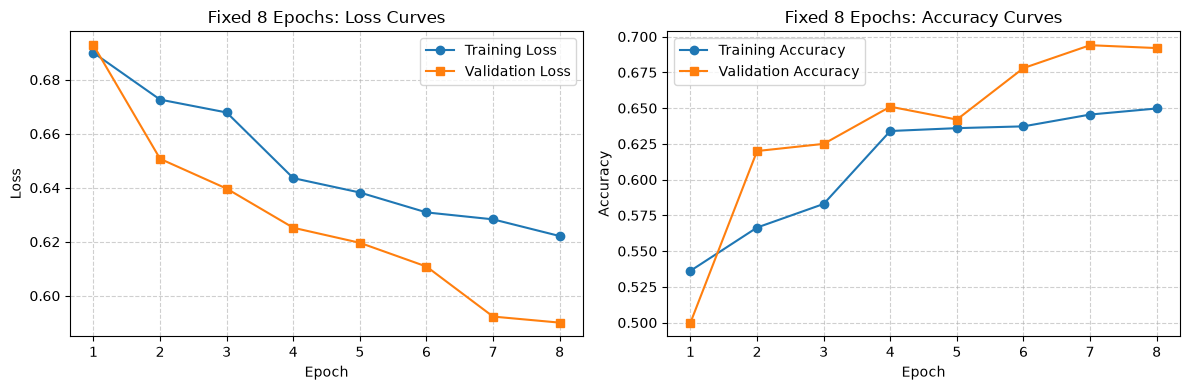

Training loss:     0.6900 (epoch 1) -> 0.6221 (epoch 8)
Training accuracy: 0.5362 (epoch 1) -> 0.6497 (epoch 8)
Lowest val loss:   0.5901 at epoch 8
Best val accuracy: 0.6940 at epoch 7


In [8]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(range(1, epochs_fixed + 1), history_fixed.history["loss"], marker="o", label="Training Loss")
plt.plot(range(1, epochs_fixed + 1), history_fixed.history["val_loss"], marker="s", label="Validation Loss")
plt.title("Fixed 8 Epochs: Loss Curves", fontsize=12)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

plt.subplot(1, 2, 2)
plt.plot(range(1, epochs_fixed + 1), history_fixed.history["accuracy"], marker="o", label="Training Accuracy")
plt.plot(range(1, epochs_fixed + 1), history_fixed.history["val_accuracy"], marker="s", label="Validation Accuracy")
plt.title("Fixed 8 Epochs: Accuracy Curves", fontsize=12)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

# Key numbers for this run (the markdown below refers to these printed values)
h_fixed = history_fixed.history
print(f"Training loss:     {h_fixed['loss'][0]:.4f} (epoch 1) -> {h_fixed['loss'][-1]:.4f} (epoch {epochs_fixed})")
print(f"Training accuracy: {h_fixed['accuracy'][0]:.4f} (epoch 1) -> {h_fixed['accuracy'][-1]:.4f} (epoch {epochs_fixed})")
print(f"Lowest val loss:   {min(h_fixed['val_loss']):.4f} at epoch {int(np.argmin(h_fixed['val_loss'])) + 1}")
print(f"Best val accuracy: {max(h_fixed['val_accuracy']):.4f} at epoch {int(np.argmax(h_fixed['val_accuracy'])) + 1}")

**Interpretation of the 8-epoch run** (the exact values are in the printed summary after the Section 6 plot):
- Training loss and training accuracy both improve across the 8 epochs.
- Validation loss is still falling at the last epoch, while validation accuracy peaks one epoch earlier in the saved run.
- Training uses augmented images with dropout active, while validation uses clean images with dropout off. I compare both models on clean images in Section 9.

**What this cell does:** builds a fresh CNN and trains it with EarlyStopping and ReduceLROnPlateau up to 12 epochs, saving the best weights in `best_model`.

In [9]:
tf.keras.utils.set_random_seed(SEED)
best_model = build_cnn()
best_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

max_epochs = 12
history_best = best_model.fit(
    train_flow,
    epochs=max_epochs,
    validation_data=val_flow,
    callbacks=[early_stopping, reduce_lr],
    verbose=2
)

Epoch 1/12


125/125 - 10s - 79ms/step - accuracy: 0.5190 - loss: 0.6965 - val_accuracy: 0.5660 - val_loss: 0.6893 - learning_rate: 0.0010


Epoch 2/12


125/125 - 9s - 73ms/step - accuracy: 0.5565 - loss: 0.6823 - val_accuracy: 0.5400 - val_loss: 0.6788 - learning_rate: 0.0010


Epoch 3/12


125/125 - 8s - 66ms/step - accuracy: 0.5723 - loss: 0.6765 - val_accuracy: 0.5820 - val_loss: 0.6677 - learning_rate: 0.0010


... (17 outputs left out)

Epoch 12/12



Epoch 12: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.


125/125 - 8s - 61ms/step - accuracy: 0.6600 - loss: 0.6068 - val_accuracy: 0.6860 - val_loss: 0.5843 - learning_rate: 5.0000e-04


Restoring model weights from the end of the best epoch: 10.


**What this cell does:** plots learning curves for the main regularized model.

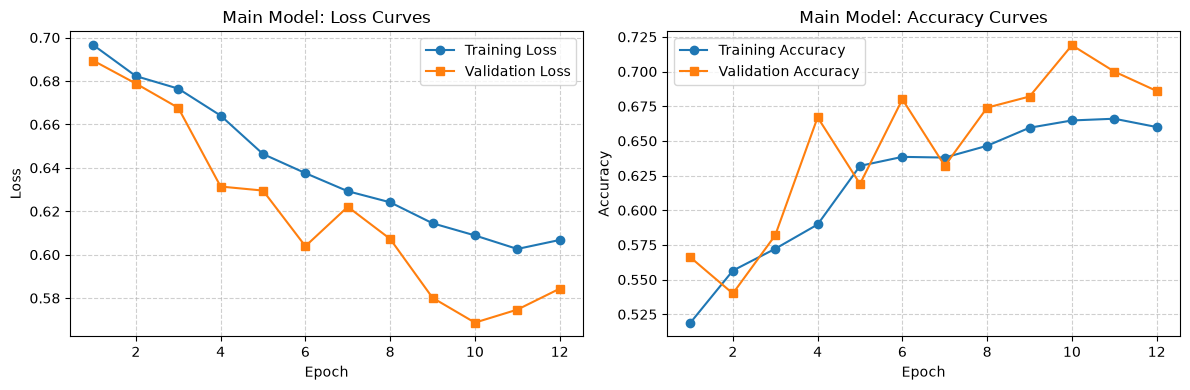

Epochs actually run:  12 (maximum was 12)
Early stopping fired: False
Restored weights from epoch 10 (val loss 0.5687, val accuracy 0.7190)
Final training loss: 0.6068, final training accuracy: 0.6600


In [10]:
actual_epochs_best = len(history_best.history["loss"])
epochs_range_best = range(1, actual_epochs_best + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs_range_best, history_best.history["loss"], marker="o", label="Training Loss")
plt.plot(epochs_range_best, history_best.history["val_loss"], marker="s", label="Validation Loss")
plt.title("Main Model: Loss Curves", fontsize=12)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

plt.subplot(1, 2, 2)
plt.plot(epochs_range_best, history_best.history["accuracy"], marker="o", label="Training Accuracy")
plt.plot(epochs_range_best, history_best.history["val_accuracy"], marker="s", label="Validation Accuracy")
plt.title("Main Model: Accuracy Curves", fontsize=12)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

# Key numbers for the main model (the markdown below refers to these printed values)
h_best = history_best.history
best_ep = int(np.argmin(h_best["val_loss"])) + 1
print(f"Epochs actually run:  {actual_epochs_best} (maximum was {max_epochs})")
print(f"Early stopping fired: {early_stopping.stopped_epoch > 0}")
print(f"Restored weights from epoch {best_ep} (val loss {h_best['val_loss'][best_ep - 1]:.4f}, val accuracy {h_best['val_accuracy'][best_ep - 1]:.4f})")
print(f"Final training loss: {h_best['loss'][-1]:.4f}, final training accuracy: {h_best['accuracy'][-1]:.4f}")

**Interpretation of the main model run:**
- The run had a maximum of 12 epochs. The printed summary shows how many actually ran and whether early stopping fired.
- The restored weights come from the epoch with the lowest validation loss, which the summary also prints.
- ReduceLROnPlateau lowers the learning rate when validation loss stalls. The epoch lines show when it fired.
- In the saved run, the final epoch had higher validation loss than the restored checkpoint. Training reached the epoch limit, and the callback still restored the lowest-loss weights.

## 7. Evaluate on validation and analyze decision thresholds

I evaluate `best_model` on the validation split (1,000 images in the saved run), compute the confusion matrix, calculate class-wise precision and recall, and analyze decision thresholds.

**What this cell does:** evaluates `best_model` on `val_flow` and generates raw probability predictions.

In [11]:
val_flow.reset()
val_eval_loss, val_eval_acc = best_model.evaluate(val_flow, verbose=0)
print(f"Validation loss:     {val_eval_loss:.4f}")
print(f"Validation accuracy: {val_eval_acc:.4f}")

val_flow.reset()
val_probs = best_model.predict(val_flow, verbose=0).ravel()
y_val_true = val_flow.classes

Validation loss:     0.5687
Validation accuracy: 0.7190


**What this cell does:** computes and plots the confusion matrix, and calculates class-wise precision, recall, and F1-scores.

Confusion Matrix (rows: True, cols: Pred):
[[387 113]
 [168 332]]

Class-wise metrics (threshold = 0.5):
Cat (class 0) -> Precision: 0.6973, Recall: 0.7740, F1: 0.7336
Dog (class 1) -> Precision: 0.7461, Recall: 0.6640, F1: 0.7026


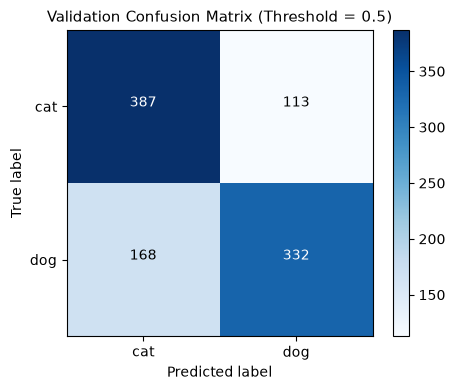

In [12]:
from sklearn.metrics import confusion_matrix, classification_report, precision_recall_fscore_support

default_threshold = 0.5
val_preds_default = (val_probs >= default_threshold).astype(int)

cm = confusion_matrix(y_val_true, val_preds_default)
print("Confusion Matrix (rows: True, cols: Pred):")
print(cm)

class_names = ["cat", "dog"]
p_cat, r_cat, f1_cat, _ = precision_recall_fscore_support(y_val_true, val_preds_default, pos_label=0, average="binary")
p_dog, r_dog, f1_dog, _ = precision_recall_fscore_support(y_val_true, val_preds_default, pos_label=1, average="binary")

print("\nClass-wise metrics (threshold = 0.5):")
print(f"Cat (class 0) -> Precision: {p_cat:.4f}, Recall: {r_cat:.4f}, F1: {f1_cat:.4f}")
print(f"Dog (class 1) -> Precision: {p_dog:.4f}, Recall: {r_dog:.4f}, F1: {f1_dog:.4f}")

# Plot confusion matrix heatmap
plt.figure(figsize=(5, 4))
plt.imshow(cm, interpolation="nearest", cmap=plt.cm.Blues)
plt.title("Validation Confusion Matrix (Threshold = 0.5)", fontsize=11)
plt.colorbar()
tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names)
plt.yticks(tick_marks, class_names)

thresh = cm.max() / 2.0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, format(cm[i, j], "d"),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

plt.ylabel("True label")
plt.xlabel("Predicted label")
plt.tight_layout()
plt.show()

In [13]:
# Which kind of error is more common? (the markdown in Section 7 refers to this printout)
fp_count = cm[0, 1]   # cats predicted as dogs
fn_count = cm[1, 0]   # dogs predicted as cats
print(f"Cats predicted as dogs: {fp_count}")
print(f"Dogs predicted as cats: {fn_count}")
if fn_count > fp_count:
    print("More dogs were called cats, so the model leans toward predicting cat.")
elif fp_count > fn_count:
    print("More cats were called dogs, so the model leans toward predicting dog.")
else:
    print("Both error types are equally common at threshold 0.5.")

Cats predicted as dogs: 113
Dogs predicted as cats: 168
More dogs were called cats, so the model leans toward predicting cat.


**Validation error analysis:**
- The loss and accuracy above are the results on the validation split. The confusion matrix (rows = true class, columns = predicted class) and the class-wise precision and recall are printed just above.
- The diagonal counts correct predictions, and the off-diagonal entries count the two error types. Precision and recall come from those same counts.

**Which error type dominates:**
In the saved run at 0.5, more dogs are called cats than cats are called dogs. Dog recall is lower, and the model predicts cat more often on this balanced validation split.

**Threshold analysis:**
I start at the usual threshold of 0.5. To see whether shifting it improves dog-class F1, I sweep thresholds from 0.10 to 0.90 below.

**What this cell does:** sweeps classification thresholds from 0.10 to 0.90 to compare dog-class F1 scores and select a threshold.

Default threshold 0.50 -> F1 score: 0.7026
Best threshold 0.35    -> F1 score: 0.7159
Adopting tuned threshold 0.35 based on validation F1 improvement.


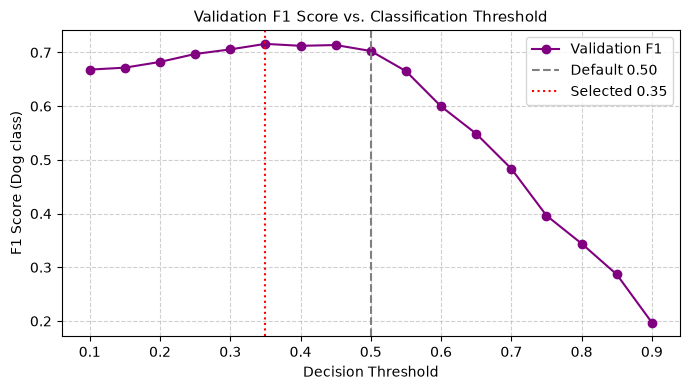

In [14]:
from sklearn.metrics import f1_score

thresholds = np.linspace(0.1, 0.9, 17)
f1_scores = []

for t in thresholds:
    preds_t = (val_probs >= t).astype(int)
    f1_scores.append(f1_score(y_val_true, preds_t))

best_idx = int(np.argmax(f1_scores))
chosen_threshold = float(thresholds[best_idx])
best_f1 = float(f1_scores[best_idx])
f1_default = float(f1_score(y_val_true, (val_probs >= 0.5).astype(int)))

print(f"Default threshold 0.50 -> F1 score: {f1_default:.4f}")
print(f"Best threshold {chosen_threshold:.2f}    -> F1 score: {best_f1:.4f}")

# If the improvement is marginal (< 0.01) on balanced classes, 0.5 is kept as standard
if abs(best_f1 - f1_default) < 0.01:
    final_threshold = 0.5
    print("Improvement is marginal on balanced data; retaining standard threshold 0.50.")
else:
    final_threshold = chosen_threshold
    print(f"Adopting tuned threshold {final_threshold:.2f} based on validation F1 improvement.")

plt.figure(figsize=(7, 4))
plt.plot(thresholds, f1_scores, marker="o", color="purple", label="Validation F1")
plt.axvline(0.5, color="gray", linestyle="--", label="Default 0.50")
plt.axvline(final_threshold, color="red", linestyle=":", label=f"Selected {final_threshold:.2f}")
plt.title("Validation F1 Score vs. Classification Threshold", fontsize=11)
plt.xlabel("Decision Threshold")
plt.ylabel("F1 Score (Dog class)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

**Threshold selection:**
The sweep tries thresholds from 0.10 to 0.90 and plots the dog-class F1 score at each one. The code keeps 0.5 unless the best threshold improves F1 by at least 0.01. The printed line says which rule applied, and that threshold is used for test inference.

Two caveats:
- I tune the threshold on the same validation split used to choose the model checkpoint. The tuned F1 may overestimate performance on fresh images. A cleaner approach would be a separate tuning split or cross-validation.
- A small F1 gain on this validation split can be noise. A lower threshold also sends more images to dog, so check the test prediction distribution in Section 8.

The right threshold depends on the application. A dog-allergy alert that must not miss any dogs would favour recall, which usually means a lower threshold. A case where false alarms are expensive would favour precision, which usually means a higher threshold.

## 8. Test set inference and predictions

I generate predictions on the unlabeled test images in `test_flow`, save them to `artifacts/test_predictions.csv`, and run a visual sanity check.

**What this cell does:** predicts probabilities on `test_flow`, constructs `df_test_preds`, and writes `artifacts/test_predictions.csv`.

In [15]:
os.makedirs("artifacts", exist_ok=True)

test_flow.reset()
test_probs = best_model.predict(test_flow, verbose=1).ravel()

test_pred_labels = ["dog" if p >= final_threshold else "cat" for p in test_probs]
test_filepaths = test_flow.filepaths

df_test_preds = pd.DataFrame({
    "filepath": test_filepaths,
    "prob_dog": test_probs,
    "pred_label": test_pred_labels
})

csv_path = "artifacts/test_predictions.csv"
df_test_preds.to_csv(csv_path, index=False)
print(f"Saved test predictions for {len(df_test_preds)} images to {csv_path}")

print("\nSample test predictions:")
print(df_test_preds.head(10))

print("\nTest prediction distribution:")
print(df_test_preds["pred_label"].value_counts())

  1/391 ━━━━━━━━━━━━━━━━━━━━ 28s 72ms/step

  3/391 ━━━━━━━━━━━━━━━━━━━━ 16s 43ms/step

  5/391 ━━━━━━━━━━━━━━━━━━━━ 17s 45ms/step

  7/391 ━━━━━━━━━━━━━━━━━━━━ 16s 43ms/step

  9/391 ━━━━━━━━━━━━━━━━━━━━ 16s 43ms/step

 11/391 ━━━━━━━━━━━━━━━━━━━━ 16s 43ms/step

... (200 outputs left out)

389/391 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step

391/391 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step

391/391 ━━━━━━━━━━━━━━━━━━━━ 17s 44ms/step


Saved test predictions for 12500 images to artifacts/test_predictions.csv

Sample test predictions:
                             filepath  prob_dog pred_label
0      data/cats_dogs/test/test/1.jpg  0.554452        dog
1     data/cats_dogs/test/test/10.jpg  0.299789        cat
2    data/cats_dogs/test/test/100.jpg  0.425941        dog
3   data/cats_dogs/test/test/1000.jpg  0.926232        dog
4  data/cats_dogs/test/test/10000.jpg  0.631470        dog
5  data/cats_dogs/test/test/10001.jpg  0.405883        dog
6  data/cats_dogs/test/test/10002.jpg  0.395416        dog
7  data/cats_dogs/test/test/10003.jpg  0.892459        dog
8  data/cats_dogs/test/test/10004.jpg  0.708355        dog
9  data/cats_dogs/test/test/10005.jpg  0.629276        dog

Test prediction distribution:
pred_label
dog    9026
cat    3474
Name: count, dtype: int64


**Manual sanity check:**
I look at 12 randomly selected test images below. Each title shows the predicted label and the model's dog score. In the saved grid, the black dog on grass gets a high dog score, while the orange cat in the first panel is called a dog with a score just above the chosen threshold. The lower-left image looks like a dog to me, but the model calls it a cat. These are visual checks on unlabeled images.

**What this cell does:** displays a random sample of 12 test images with predicted labels and dog scores for visual sanity verification.

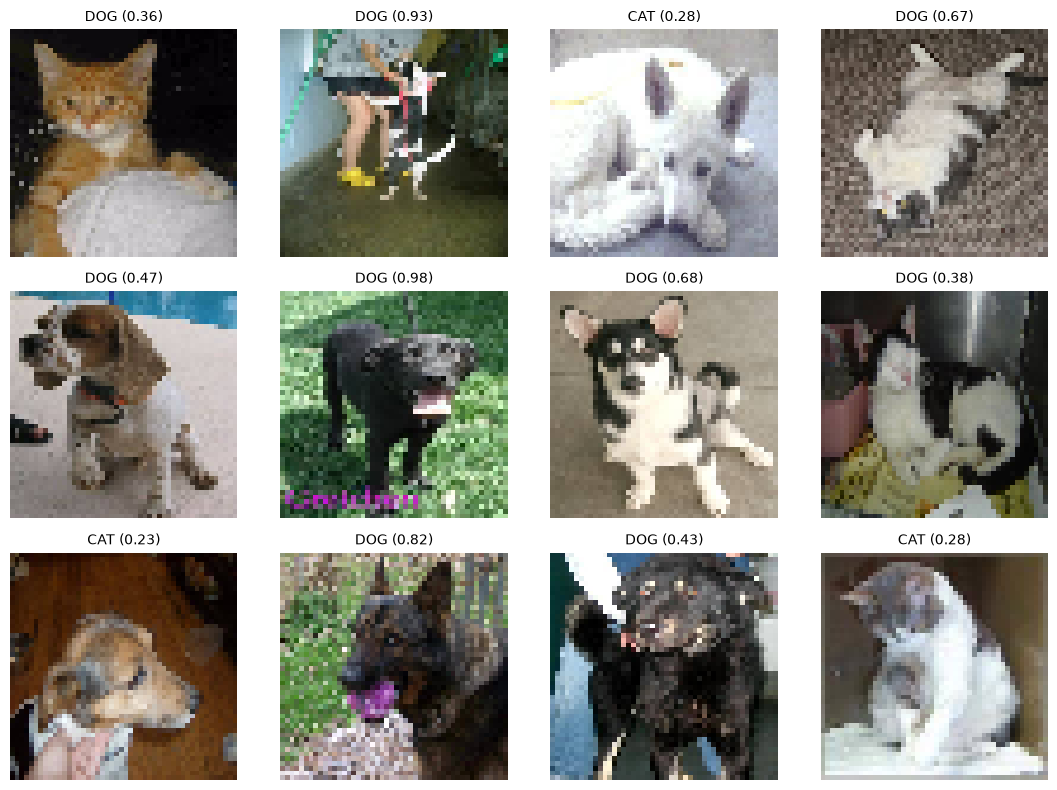

In [16]:
from tensorflow.keras.preprocessing.image import load_img, img_to_array

np.random.seed(SEED)
sample_indices = np.random.choice(len(df_test_preds), size=12, replace=False)

plt.figure(figsize=(11, 8))
for idx, sample_idx in enumerate(sample_indices):
    row = df_test_preds.iloc[sample_idx]
    img = load_img(row["filepath"], target_size=(IMG_HEIGHT, IMG_WIDTH))
    
    plt.subplot(3, 4, idx + 1)
    plt.imshow(img)
    plt.title(f"{row['pred_label'].upper()} ({row['prob_dog']:.2f})", fontsize=10)
    plt.axis("off")

plt.tight_layout()
plt.show()

## 9. Baseline vs Data Augmentation experiment

To isolate the impact of data augmentation, I train an identical CNN architecture on the exact same `df_tr` and `df_val` splits using a simple non-augmented generator (`rescale=1./255` only).
I use the same model and training settings for both: Adam optimizer with learning rate `1e-3`, batch size 32, `EarlyStopping(patience=3)`, `ReduceLROnPlateau(patience=2)`, and a maximum of 12 epochs.

**What this cell does:** creates an unaugmented training generator and trains an identical baseline CNN.

In [17]:
# Unaugmented generator (rescale only)
train_datagen_base = ImageDataGenerator(rescale=1.0 / 255.0)

train_flow_base = train_datagen_base.flow_from_dataframe(
    dataframe=df_tr,
    x_col="filepath",
    y_col="label",
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=True,
    seed=seed,
    validate_filenames=False
)

tf.keras.utils.set_random_seed(SEED)
baseline_model = build_cnn()
baseline_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history_base = baseline_model.fit(
    train_flow_base,
    epochs=12,
    validation_data=val_flow,
    callbacks=[
        EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5, verbose=1)
    ],
    verbose=2
)

Found 4000 validated image filenames belonging to 2 classes.


Epoch 1/12


125/125 - 8s - 60ms/step - accuracy: 0.5640 - loss: 0.6799 - val_accuracy: 0.6510 - val_loss: 0.6357 - learning_rate: 0.0010


Epoch 2/12


125/125 - 6s - 49ms/step - accuracy: 0.6457 - loss: 0.6256 - val_accuracy: 0.6800 - val_loss: 0.5988 - learning_rate: 0.0010


Epoch 3/12


... (18 outputs left out)

Epoch 12/12


125/125 - 6s - 45ms/step - accuracy: 0.8640 - loss: 0.3072 - val_accuracy: 0.7510 - val_loss: 0.5540 - learning_rate: 5.0000e-04


Epoch 12: early stopping


Restoring model weights from the end of the best epoch: 9.


**What this cell does:** overlays the learning curves of the baseline unaugmented model against the augmented model.

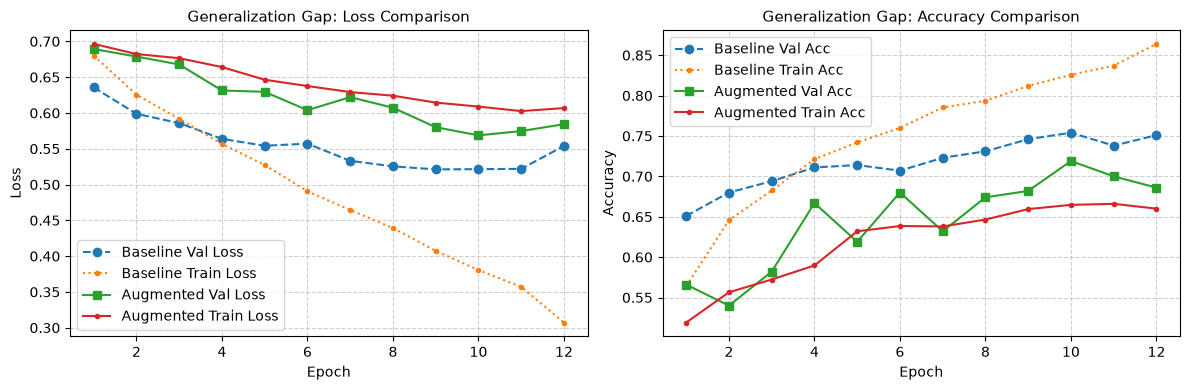

Baseline:  Train Acc=0.8742, Val Acc=0.7460, Gap=0.1283
Augmented: Train Acc=0.7135, Val Acc=0.7190, Gap=-0.0055
Baseline best epoch: 9, augmented best epoch: 10


In [18]:
plt.figure(figsize=(12, 4))

# Use the same 1-based epoch numbering as the training logs.
base_epochs = range(1, len(history_base.history["loss"]) + 1)

# Loss overlay
plt.subplot(1, 2, 1)
plt.plot(base_epochs, history_base.history["val_loss"], marker="o", linestyle="--", label="Baseline Val Loss")
plt.plot(base_epochs, history_base.history["loss"], marker=".", linestyle=":", label="Baseline Train Loss")
plt.plot(epochs_range_best, history_best.history["val_loss"], marker="s", linestyle="-", label="Augmented Val Loss")
plt.plot(epochs_range_best, history_best.history["loss"], marker=".", linestyle="-", label="Augmented Train Loss")
plt.title("Generalization Gap: Loss Comparison", fontsize=11)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

# Accuracy overlay
plt.subplot(1, 2, 2)
plt.plot(base_epochs, history_base.history["val_accuracy"], marker="o", linestyle="--", label="Baseline Val Acc")
plt.plot(base_epochs, history_base.history["accuracy"], marker=".", linestyle=":", label="Baseline Train Acc")
plt.plot(epochs_range_best, history_best.history["val_accuracy"], marker="s", linestyle="-", label="Augmented Val Acc")
plt.plot(epochs_range_best, history_best.history["accuracy"], marker=".", linestyle="-", label="Augmented Train Acc")
plt.title("Generalization Gap: Accuracy Comparison", fontsize=11)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

# Quantitative comparison
val_base_loss, val_base_acc = baseline_model.evaluate(val_flow, verbose=0)
train_base_loss, train_base_acc = baseline_model.evaluate(train_flow_base, verbose=0)
# Score both models on the same unaugmented training images so the gap is a fair comparison
train_aug_loss, train_aug_acc = best_model.evaluate(train_flow_base, verbose=0)

gap_base = train_base_acc - val_base_acc
gap_aug = train_aug_acc - val_eval_acc

print(f"Baseline:  Train Acc={train_base_acc:.4f}, Val Acc={val_base_acc:.4f}, Gap={gap_base:.4f}")
print(f"Augmented: Train Acc={train_aug_acc:.4f}, Val Acc={val_eval_acc:.4f}, Gap={gap_aug:.4f}")
print(f"Baseline best epoch: {int(np.argmin(history_base.history['val_loss'])) + 1}, augmented best epoch: {int(np.argmin(history_best.history['val_loss'])) + 1}")

**Generalization gap analysis:**
I score both restored models on the same unaugmented training images and on the same validation split. The printed gap is training accuracy minus validation accuracy. The training curves above show metrics from the fit itself, when dropout was active and the augmented model saw transformed images.

In the saved run, the baseline has a larger positive gap. The augmented model has a small negative gap, so its clean training and validation accuracies are close. The baseline still has higher validation accuracy and lower validation loss at the restored checkpoints. I select those checkpoints by minimum validation loss. The baseline's highest validation accuracy during training occurs one epoch after its lowest loss.

The saved overlay uses the values printed in the training logs, rounded to four decimal places.

## 10. Class imbalance check

I verify class balance across the training split and compute inverse-frequency class weights using scikit-learn's `compute_class_weight`.

**What this cell does:** computes class counts and balanced class weights for the training set.

In [19]:
from sklearn.utils.class_weight import compute_class_weight

tr_labels_num = (df_tr["label"] == "dog").astype(int).values
classes = np.unique(tr_labels_num)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=tr_labels_num
)
class_weight_dict = dict(zip(classes, class_weights))

print("Training class counts:")
print(df_tr["label"].value_counts())
print("\nComputed class weights:")
for cls_idx, weight in class_weight_dict.items():
    cls_name = "cat" if cls_idx == 0 else "dog"
    print(f"Class {cls_idx} ({cls_name}): {weight:.4f}")

Training class counts:
label
dog    2000
cat    2000
Name: count, dtype: int64

Computed class weights:
Class 0 (cat): 1.0000
Class 1 (dog): 1.0000


**Class imbalance assessment:**
In the saved run, the training set contains exactly 2,000 cats and 2,000 dogs.
The computed class weights are 1.0000 for cat and 1.0000 for dog.
Because both weights are exactly 1.0 in this run, I keep the original fit.

**What class_weight does in imbalanced domains:**
If an imbalanced dataset had a heavy class skew (such as a 9-to-1 ratio), a naive network could attain a superficially high accuracy by always predicting the majority class, completely failing on the minority class.
By assigning class weights inversely proportional to class frequencies, the loss contribution of minority samples is scaled upward:
$$w_j = \frac{N}{K \cdot n_j}$$
This makes each minority-class example count more in the loss. I would still check recall for both classes after training.

## 11. Save model and run metadata

I save the trained model and the settings needed to interpret the run and use the model for inference.

**Why weights and metadata are both necessary:**
Saving the model file (`.keras`) preserves the trained tensor weights and neural computational graph. However, weights alone do not record:
1. Input preprocessing parameters (normalization divisor 255.0, image resolution 48×48).
2. Data augmentation hyperparameter bounds (rotation range, shifts, zoom, and horizontal flips).
3. The official loader split seed (1337) and the NumPy/TensorFlow seed (42).
4. The post-processing decision threshold chosen in Section 7 (saved as `final_threshold`).
The model and config together tell me how to prepare a new image and turn the dog score into a label.

**What this cell does:** exports model weights, training configuration JSON, and execution run log.

In [20]:
import json
import sys
import platform
from datetime import datetime

artifacts_dir = Path("artifacts")
artifacts_dir.mkdir(parents=True, exist_ok=True)

# 1. Save best model weights
model_path = artifacts_dir / "cats_vs_dogs_cnn.keras"
best_model.save(model_path)
print(f"Saved best model to {model_path}")

# 2. Write training config JSON
config = {
    "dataset": "Dogs vs Cats (devtlv GitHub mirror)",
    "image_height": IMG_HEIGHT,
    "image_width": IMG_WIDTH,
    "batch_size": BATCH_SIZE,
    "subsample_size": len(df_train_full),
    "train_size": len(df_tr),
    "val_size": len(df_val),
    "test_size": len(df_test),
    "seed": SEED,
    "loader_seed": LOADER_SEED,
    "architecture": "2x(Conv2D+MaxPool2D+Dropout) -> Flatten -> Dense(128, ReLU)+Dropout(0.5) -> Dense(1, Sigmoid)",
    "conv_filters": [32, 64],
    "dense_units": 128,
    "preprocessing": {"rescale": train_gen.rescale, "interpolation": val_flow.interpolation},
    "augmentation": {
        "rotation_range": train_gen.rotation_range,
        "width_shift_range": train_gen.width_shift_range,
        "height_shift_range": train_gen.height_shift_range,
        "zoom_range": list(train_gen.zoom_range),
        "horizontal_flip": train_gen.horizontal_flip
    },
    "optimizer": "Adam",
    "learning_rate": 1e-3,
    "loss": "binary_crossentropy",
    "callbacks": [
        "EarlyStopping(monitor=val_loss, patience=3, restore_best_weights=True)",
        "ReduceLROnPlateau(monitor=val_loss, factor=0.5, patience=2, min_lr=1e-5)"
    ],
    "epochs_trained_augmented": len(history_best.history["loss"]),
    "epochs_trained_baseline": len(history_base.history["loss"]),
    "final_threshold": final_threshold,
    "model_path": str(model_path),
    "predictions_csv": csv_path
}

config_path = artifacts_dir / "training_config.json"
with open(config_path, "w", encoding="utf-8") as f:
    json.dump(config, f, indent=4)
print(f"Saved configuration to {config_path}")

# 3. Write run log
log_path = artifacts_dir / "run_log.txt"
with open(log_path, "w", encoding="utf-8") as f:
    f.write("=== Cats vs Dogs CNN Training Run Log ===\n")
    f.write(f"Timestamp:          {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}\n")
    f.write(f"Python Version:     {platform.python_version()}\n")
    f.write(f"TensorFlow Version: {tf.__version__}\n")
    f.write(f"Platform:           {platform.platform()}\n")
    f.write(f"Subsample Size:     {len(df_train_full)} (Train: {len(df_tr)}, Val: {len(df_val)})\n")
    f.write(f"Augmented Best Val Loss:     {val_eval_loss:.4f}\n")
    f.write(f"Augmented Val Accuracy at Restored Epoch: {val_eval_acc:.4f}\n")
    f.write(f"Baseline Val Loss:           {val_base_loss:.4f}\n")
    f.write(f"Baseline Val Accuracy:       {val_base_acc:.4f}\n")
    f.write(f"Generalization Gap (Aug):    {gap_aug:.4f}\n")
    f.write(f"Generalization Gap (Base):   {gap_base:.4f}\n")
    f.write(f"Selected Decision Threshold: {final_threshold:.2f}\n")
    f.write("Artifacts Exported Successfully.\n")
print(f"Saved run log to {log_path}")

Saved best model to artifacts/cats_vs_dogs_cnn.keras
Saved configuration to artifacts/training_config.json
Saved run log to artifacts/run_log.txt


## 12. Extensions: Transfer Learning with MobileNetV2

As a natural extension to this custom CNN, I propose transfer learning with a pre-trained **MobileNetV2** backbone (ImageNet weights). MobileNetV2 uses depthwise separable convolutions and inverted residual blocks to extract features efficiently. The plan would be to load it with ImageNet weights, freeze the convolutional base, and add a small head (a `GlobalAveragePooling2D` layer, a `Dense(128, activation='relu')` with `Dropout(0.3)`, and a `Dense(1, activation='sigmoid')` output). The pre-trained filters (edges, textures and shapes learned from ImageNet) should help the classifier converge in fewer epochs, especially on a small training set.

I deliberately do not run it here. MobileNetV2 is designed for larger inputs (224×224 by default). At 48×48 its feature maps become very small, so the pre-trained features would be used far outside the resolution they were designed for. I would measure CPU runtime if I tried it.

## 13. Deliverables checklist

- [x] **1. Colab-ready notebook:** Fully functional, structured in first-person student voice, with section headers, markdown explanations, and settings for re-running on CPU.
- [x] **2. Data pipeline and subsampling:** Implemented `ensure_dataset()` download/extraction, stratified subsampling to 5,000 images, 80/20 train/validation split, and `ImageDataGenerator` data augmentation.
- [x] **3. Baseline vs. augmented comparison:** Trained an identical unaugmented baseline CNN and compared restored checkpoint performance through learning curve overlays and generalization gap analysis.
- [x] **4. Validation error analysis:** Evaluated the best augmented model, plotted the confusion matrix, computed class-wise precision/recall, and analyzed decision thresholds.
- [x] **5. Test set inference:** Generated predictions on the unlabeled test images, saved `artifacts/test_predictions.csv`, and performed visual sanity checks.
- [x] **6. Saved artifacts:** Exported model weights (`cats_vs_dogs_cnn.keras`), training configuration (`training_config.json`), execution log (`run_log.txt`), and comprehensive metrics (`metrics.json`).

## 14. Export metrics JSON

Finally, I write the training and evaluation summary, including class counts and selected epochs to `artifacts/metrics.json` so they can be easily reviewed and verified.

**What this cell does:** writes the run summary to `artifacts/metrics.json`.

In [21]:
metrics_data = {
    "class_counts": {
        "full_labeled_pool": full_labeled_pool_size,
        "subsample_total": len(df_train_full),
        "subsample_cats": int((df_train_full["label"] == "cat").sum()),
        "subsample_dogs": int((df_train_full["label"] == "dog").sum()),
        "train_set_size": len(df_tr),
        "val_set_size": len(df_val),
        "test_set_size": len(df_test)
    },
    "fixed_8_epochs": {
        "epochs": epochs_fixed,
        "final_train_loss": float(history_fixed.history["loss"][-1]),
        "final_train_acc": float(history_fixed.history["accuracy"][-1]),
        "final_val_loss": float(history_fixed.history["val_loss"][-1]),
        "final_val_acc": float(history_fixed.history["val_accuracy"][-1])
    },
    "main_augmented_model": {
        "epochs_trained": actual_epochs_best,
        "best_epoch": int(np.argmin(history_best.history["val_loss"]) + 1),
        "best_val_loss": float(val_eval_loss),
        "val_accuracy_at_best_epoch": float(val_eval_acc),
        "final_train_loss": float(history_best.history["loss"][-1]),
        "final_train_accuracy": float(history_best.history["accuracy"][-1]),
        "restored_clean_train_loss": float(train_aug_loss),
        "restored_clean_train_accuracy": float(train_aug_acc),
        "generalization_gap": float(gap_aug)
    },
    "baseline_model": {
        "epochs_trained": len(history_base.history["loss"]),
        "best_epoch": int(np.argmin(history_base.history["val_loss"]) + 1),
        "best_val_loss": float(val_base_loss),
        "val_accuracy_at_best_epoch": float(val_base_acc),
        "restored_clean_train_loss": float(train_base_loss),
        "restored_clean_train_accuracy": float(train_base_acc),
        "generalization_gap": float(gap_base)
    },
    "validation_evaluation": {
        "confusion_matrix": {
            "true_cats": int(cm[0, 0]),
            "false_dogs": int(cm[0, 1]),
            "false_cats": int(cm[1, 0]),
            "true_dogs": int(cm[1, 1])
        },
        "metrics_cat": {
            "precision": float(p_cat),
            "recall": float(r_cat),
            "f1": float(f1_cat)
        },
        "metrics_dog": {
            "precision": float(p_dog),
            "recall": float(r_dog),
            "f1": float(f1_dog)
        },
        "default_threshold": 0.5,
        "optimal_threshold": float(chosen_threshold),
        "final_threshold": float(final_threshold),
        "default_f1": float(f1_default),
        "optimal_f1": float(best_f1)
    },
    "test_predictions": {
        "total_predicted": len(df_test_preds),
        "predicted_cats": int((df_test_preds["pred_label"] == "cat").sum()),
        "predicted_dogs": int((df_test_preds["pred_label"] == "dog").sum())
    }
}

metrics_json_path = artifacts_dir / "metrics.json"
with open(metrics_json_path, "w", encoding="utf-8") as f:
    json.dump(metrics_data, f, indent=4)

print(f"Metrics written successfully to {metrics_json_path}")

Metrics written successfully to artifacts/metrics.json
